# Phase 2: Per-layer sensitivity analysis (llama.cpp on Kaggle)

**Question:** which parts of the model can be compressed hard without hurting quality, and which parts cannot?

**Method (one-at-a-time ablation):** start from a near-lossless model (every weight at Q8_0). Drop ONE part to a low precision (Q2_K) and measure the perplexity increase.
- **Per block:** each of the transformer blocks, one at a time.
- **Per tensor kind:** attn_q, attn_k, attn_v, attn_output, ffn_gate, ffn_up, ffn_down (all blocks at once) and the token embeddings.

**Proof of concept for the project's core claim:** build mixed configs from the sensitivity ranking ("compress the most tolerant blocks first") and compare them against (a) uniform quantization (Q6_K ... Q2_K) and (b) random block choices at the same size. If guided beats random and uniform at equal size, the search in Phase 3 is justified.

**Before running:** Accelerator = GPU T4 x2 or P100, Internet = On.
**Time (rough estimate):** about 15-25 min of setup (llama.cpp build, model download, conversion), then roughly 60 evaluations of about 1 min each. Every result is appended to a JSONL file, so an interrupted run resumes.

**Reading the numbers:** perplexity is measured on the same text for every config, so *differences* between configs are more reliable than the +/- error printed per model. Still, treat changes below about 0.5% as noise.

In [2]:
import os, json, re, time, subprocess, pathlib, shutil, random

# Benchmark on ONE GPU even if Kaggle gives T4 x2
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

MODEL_ID   = "Qwen/Qwen2.5-1.5B"
MODEL_NAME = MODEL_ID.split("/")[-1]

HIGH       = "q8_0"      # precision of everything NOT under test (near-lossless)
LOW_TYPES  = ["q2_k"]    # precision applied to the part under test; add "q4_k" for a milder second probe
UNIFORM    = ["Q6_K", "Q5_K_M", "Q4_K_M", "Q3_K_M", "Q2_K"]   # standard presets for comparison
STEPS      = [4, 8, 12, 16, 20, 24]   # how many blocks get compressed in the guided/random configs
RANDOM_SEEDS = [0, 1]
PPL_CHUNKS = 100         # 512-token chunks of WikiText-2 test; None = full set
CLEANUP    = True        # delete big model files at the very end so Save Version stays fast

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5


## 1. Build llama.cpp (only the two tools this phase needs)

In [3]:
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone --depth 1 https://github.com/ggml-org/llama.cpp {LLAMA}")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"

    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-perplexity")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT)
help_txt = sh(f"{BIN/'llama-quantize'} --help", check=False)
print("per-tensor override flag available:", "--tensor-type" in help_txt)

$ git clone --depth 1 https://github.com/ggml-org/llama.cpp /kaggle/working/llama.cpp
$ cmake --build /kaggle/working/llama.cpp/build --config Release -j 4 --target llama-quantize llama-perplexity
$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: 970b51c
$ /kaggle/working/llama.cpp/build/bin/llama-quantize --help
per-tensor override flag available: True


## 2. Model, F16 GGUF and evaluation text

In [4]:
sh(f"pip install -q {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID,
    local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"],
)
N_BLOCKS = json.load(open(pathlib.Path(hf_dir) / "config.json"))["num_hidden_layers"]
print("transformer blocks:", N_BLOCKS)

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

WIKI = WORK / "wiki.test.raw"
if not WIKI.exists():
    try:
        from datasets import load_dataset
        ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
        text = "".join(ds["text"])
    except Exception as e:
        print("datasets route failed, downloading parquet directly:", repr(e)[:200])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", "wikitext-2-raw-v1/test-00000-of-00001.parquet",
                            repo_type="dataset")
        text = "".join(pd.read_parquet(p)["text"])
    WIKI.write_text(text)
print(f"{WIKI.stat().st_size/1e6:.1f} MB of eval text")

$ pip install -q /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

transformer blocks: 28
$ python /kaggle/working/llama.cpp/convert_hf_to_gguf.py /kaggle/working/hf/Qwen2.5-1.5B --outfile /kaggle/working/models/Qwen2.5-1.5B-F16.gguf --outtype f16
Qwen2.5-1.5B-F16.gguf 3094 MB


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

datasets route failed, downloading parquet directly: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")


wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

1.3 MB of eval text


## 3. Helpers: per-tensor quantization, perplexity, tensor-type check
`llama-quantize --tensor-type REGEX=TYPE` overrides the type of every tensor whose name matches the regex (can be repeated). Tensor names look like `blk.5.ffn_down.weight`.

In [5]:
QUANT  = str(BIN / "llama-quantize")
PPLBIN = str(BIN / "llama-perplexity")
KINDS  = ["attn_q", "attn_k", "attn_v", "attn_output", "ffn_gate", "ffn_up", "ffn_down"]

def block_regex(ids):
    # matches the 7 weight matrices of the listed blocks, e.g. blk.5.ffn_down.weight
    return r"blk\.(" + "|".join(str(i) for i in ids) + r")\.(" + "|".join(KINDS) + r")\.weight"

def kind_regex(kind):
    return r"blk\.\d+\." + kind + r"\.weight"

def run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError("failed: " + " ".join(map(str, cmd))[:300])
    return r.stdout + r.stderr

def quantize(out, base, overrides=()):
    cmd = [QUANT]
    for pattern, qtype in overrides:
        cmd += ["--tensor-type", f"{pattern}={qtype}"]
    cmd += [str(F16), str(out), base]
    run(cmd)

def perplexity(path):
    cmd = [PPLBIN, "-m", str(path), "-f", str(WIKI), "-ngl", "99", "-c", "512"]
    if PPL_CHUNKS:
        cmd += ["--chunks", str(PPL_CHUNKS)]
    out = run(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", out)
    if not m:
        raise RuntimeError(out[-2000:])
    return float(m.group(1)), float(m.group(2))

def tensor_types(path):
    from gguf import GGUFReader
    return {t.name: t.tensor_type.name for t in GGUFReader(str(path)).tensors}

RESULTS_FILE = RESULTS / f"phase2_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["name"]] = r

def evaluate(name, base, overrides=(), **meta):
    # quantize -> perplexity -> record -> delete the temporary GGUF (disk is limited)
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, base, overrides)
    ppl, err = perplexity(out)
    rec = {"name": name, "base": base, "size_mb": out.stat().st_size / 1e6,
           "ppl": ppl, "ppl_err": err, **meta}
    out.unlink()
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"{name:28s} size={rec['size_mb']:7.0f} MB  ppl={ppl:7.3f}  ({time.time()-t:.0f}s)")
    return rec

## 4. Self-test: do the per-tensor overrides really apply?
This reads the tensor types straight from the output file. If this cell fails, nothing after it can be trusted, so fix it first.

In [6]:
test = MODELS / "selftest.gguf"
quantize(test, HIGH, [(block_regex([0]), "q2_k")])
tt = tensor_types(test)
a, b = tt["blk.0.ffn_down.weight"], tt["blk.1.ffn_down.weight"]
print("blk.0.ffn_down:", a, "| blk.1.ffn_down:", b)
from collections import Counter
print(Counter(tt.values()))
test.unlink()
assert a == "Q2_K" and b == "Q8_0", (
    "tensor overrides were not applied as expected. Check `llama-quantize --help` for the "
    "--tensor-type syntax in this llama.cpp version and paste the output here.")
print("OK: per-tensor overrides work")

blk.0.ffn_down: Q2_K | blk.1.ffn_down: Q8_0
Counter({'Q8_0': 190, 'F32': 141, 'Q2_K': 7})
OK: per-tensor overrides work


## 5. Reference points
- `ref_F16`: the unquantized model
- `ref_HIGH`: everything at Q8_0 (the starting point for every ablation)
- `ref_LOW`: everything at the low type (the worst case)

In [7]:
if "ref_F16" not in records:
    ppl, err = perplexity(F16)
    records["ref_F16"] = {"name": "ref_F16", "base": "f16", "size_mb": F16.stat().st_size / 1e6,
                          "ppl": ppl, "ppl_err": err, "group": "ref"}
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(records["ref_F16"]) + "\n")
print("ref_F16", records["ref_F16"]["size_mb"], records["ref_F16"]["ppl"])

evaluate("ref_HIGH", HIGH, group="ref")
for low in LOW_TYPES:
    evaluate(f"ref_LOW_{low}", low, group="ref")
ref = records["ref_HIGH"]

ref_F16 3093.668832 9.6817
ref_HIGH                     size=   1647 MB  ppl=  9.702  (39s)
ref_LOW_q2_k                 size=    676 MB  ppl= 22.720  (83s)


## 6. Sweep A: one transformer block at a time
For each block `i`: block `i` at the low type, everything else at HIGH. About 1 minute each.

In [8]:
for low in LOW_TYPES:
    for i in range(N_BLOCKS):
        evaluate(f"block{i:02d}_{low}", HIGH, [(block_regex([i]), low)],
                 group="block", block=i, low=low)

block00_q2_k                 size=   1612 MB  ppl= 10.217  (41s)
block01_q2_k                 size=   1612 MB  ppl= 10.733  (41s)
block02_q2_k                 size=   1612 MB  ppl= 10.174  (41s)
block03_q2_k                 size=   1612 MB  ppl=  9.974  (41s)
block04_q2_k                 size=   1612 MB  ppl=  9.861  (41s)
block05_q2_k                 size=   1612 MB  ppl= 10.061  (41s)
block06_q2_k                 size=   1612 MB  ppl=  9.907  (41s)
block07_q2_k                 size=   1612 MB  ppl=  9.855  (41s)
block08_q2_k                 size=   1612 MB  ppl=  9.919  (41s)
block09_q2_k                 size=   1612 MB  ppl=  9.907  (42s)
block10_q2_k                 size=   1612 MB  ppl=  9.880  (41s)
block11_q2_k                 size=   1612 MB  ppl=  9.910  (41s)
block12_q2_k                 size=   1612 MB  ppl=  9.911  (41s)
block13_q2_k                 size=   1612 MB  ppl=  9.922  (41s)
block14_q2_k                 size=   1612 MB  ppl=  9.911  (41s)
block15_q2_k             

## 7. Sweep B: one tensor kind at a time (all blocks together)

In [9]:
for low in LOW_TYPES:
    for k in KINDS:
        evaluate(f"kind_{k}_{low}", HIGH, [(kind_regex(k), low)], group="kind", kind=k, low=low)
    evaluate(f"kind_token_embd_{low}", HIGH, [(r"token_embd\.weight", low)],
             group="kind", kind="token_embd", low=low)

kind_attn_q_q2_k             size=   1598 MB  ppl= 10.005  (42s)
kind_attn_k_q2_k             size=   1638 MB  ppl= 10.004  (39s)
kind_attn_v_q2_k             size=   1638 MB  ppl= 11.155  (39s)
kind_attn_output_q2_k        size=   1598 MB  ppl= 10.614  (41s)
kind_ffn_gate_q2_k           size=   1364 MB  ppl= 11.412  (54s)
kind_ffn_up_q2_k             size=   1364 MB  ppl= 12.404  (55s)
kind_ffn_down_q2_k           size=   1364 MB  ppl= 13.226  (54s)
kind_token_embd_q2_k         size=   1475 MB  ppl= 16.831  (48s)


## 8. Sensitivity results
`d_ppl_pct` is the perplexity increase over `ref_HIGH`. `pct_per_mb` divides that by the megabytes saved, so it measures **damage per MB saved**: the lower, the better a candidate for compression.

reference: F16 ppl=9.682, Q8_0 ppl=9.702, all-q2_k ppl=22.720

Most sensitive blocks (keep precise):


,block,d_ppl_pct,mb_saved,pct_per_mb
27,27,15.224,34.363,0.443
1,1,10.633,34.363,0.309
0,0,5.312,34.363,0.155
2,2,4.865,34.363,0.142
21,21,4.087,34.363,0.119


Most tolerant blocks (compress first):


,block,d_ppl_pct,mb_saved,pct_per_mb
7,7,1.576,34.363,0.046
4,4,1.641,34.363,0.048
10,10,1.838,34.363,0.053
6,6,2.113,34.363,0.061
9,9,2.114,34.363,0.062


Tensor kinds:


,kind,d_ppl_pct,mb_saved,pct_per_mb
0,token_embd,73.487,171.384,0.429
1,ffn_down,36.322,282.993,0.128
2,ffn_up,27.855,282.993,0.098
3,ffn_gate,17.629,282.993,0.062
4,attn_v,14.980,8.086,1.853
5,attn_output,9.407,48.513,0.194
6,attn_q,3.120,48.513,0.064
7,attn_k,3.116,8.086,0.385


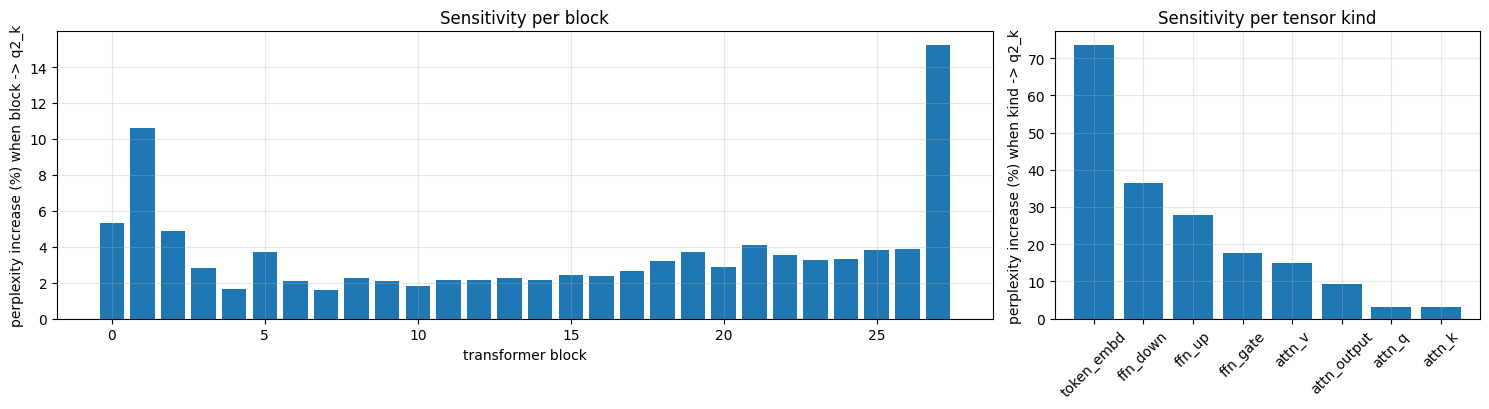

compression order (first = most tolerant): [7, 4, 10, 6, 9, 11, 14, 12, 8, 13, 16, 15, 17, 3, 20, 18, 23, 24, 22, 5, 19, 25, 26, 21, 2, 0, 1, 27]


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

low0 = LOW_TYPES[0]
def table(group):
    d = pd.DataFrame([r for r in records.values() if r.get("group") == group])
    d = d[d.low == low0].copy()
    d["d_ppl_pct"] = (d.ppl / ref["ppl"] - 1) * 100
    d["mb_saved"] = ref["size_mb"] - d.size_mb
    d["pct_per_mb"] = d.d_ppl_pct / d.mb_saved
    return d

blk = table("block").sort_values("block").reset_index(drop=True)
kinds = table("kind").sort_values("d_ppl_pct", ascending=False).reset_index(drop=True)

print(f"reference: F16 ppl={records['ref_F16']['ppl']:.3f}, Q8_0 ppl={ref['ppl']:.3f}, "
      f"all-{low0} ppl={records['ref_LOW_' + low0]['ppl']:.3f}")
print("\nMost sensitive blocks (keep precise):")
display(blk.nlargest(5, "d_ppl_pct")[["block", "d_ppl_pct", "mb_saved", "pct_per_mb"]].round(3))
print("Most tolerant blocks (compress first):")
display(blk.nsmallest(5, "d_ppl_pct")[["block", "d_ppl_pct", "mb_saved", "pct_per_mb"]].round(3))
print("Tensor kinds:")
display(kinds[["kind", "d_ppl_pct", "mb_saved", "pct_per_mb"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].bar(blk.block, blk.d_ppl_pct)
ax[0].set_xlabel("transformer block"); ax[0].set_ylabel(f"perplexity increase (%) when block -> {low0}")
ax[0].set_title("Sensitivity per block"); ax[0].grid(alpha=.3)
ax[1].bar(kinds.kind, kinds.d_ppl_pct)
ax[1].set_ylabel(f"perplexity increase (%) when kind -> {low0}")
ax[1].set_title("Sensitivity per tensor kind"); ax[1].tick_params(axis="x", rotation=45); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(RESULTS / f"phase2_{MODEL_NAME}_sensitivity.png", dpi=150)
plt.show()

# blocks ordered from most tolerant to most sensitive (damage per MB saved)
order_guided = blk.sort_values("pct_per_mb")["block"].astype(int).tolist()
print("compression order (first = most tolerant):", order_guided)

## 9. Does sensitivity-guided allocation beat the alternatives?
For N = 4, 8, ... blocks compressed to the low type, rest at HIGH, compare:
- **guided:** the N most tolerant blocks (from the ranking above)
- **random:** N random blocks (a few seeds), the control for "does the ranking matter?"
- **uniform:** the standard presets (Q6_K ... Q2_K)

In [11]:
low = low0
for n in STEPS:
    evaluate(f"guided_N{n:02d}_{low}", HIGH, [(block_regex(order_guided[:n]), low)],
             group="guided", n_low=n, low=low)
    for seed in RANDOM_SEEDS:
        order = list(range(N_BLOCKS)); random.Random(seed).shuffle(order)
        evaluate(f"random{seed}_N{n:02d}_{low}", HIGH, [(block_regex(order[:n]), low)],
                 group="random", n_low=n, seed=seed, low=low)

for q in UNIFORM:
    evaluate(f"uniform_{q}", q, group="uniform")

guided_N04_q2_k              size=   1509 MB  ppl= 10.608  (47s)
random0_N04_q2_k             size=   1509 MB  ppl= 10.744  (46s)
random1_N04_q2_k             size=   1509 MB  ppl= 10.868  (47s)
guided_N08_q2_k              size=   1372 MB  ppl= 12.157  (54s)
random0_N08_q2_k             size=   1372 MB  ppl= 13.604  (54s)
random1_N08_q2_k             size=   1372 MB  ppl= 15.280  (58s)
guided_N12_q2_k              size=   1234 MB  ppl= 14.886  (69s)
random0_N12_q2_k             size=   1234 MB  ppl= 16.227  (69s)
random1_N12_q2_k             size=   1234 MB  ppl= 18.052  (69s)
guided_N16_q2_k              size=   1097 MB  ppl= 18.280  (77s)
random0_N16_q2_k             size=   1097 MB  ppl= 25.264  (78s)
random1_N16_q2_k             size=   1097 MB  ppl= 24.832  (77s)
guided_N20_q2_k              size=    959 MB  ppl= 23.457  (85s)
random0_N20_q2_k             size=    959 MB  ppl= 32.966  (85s)
random1_N20_q2_k             size=    959 MB  ppl= 33.490  (84s)
guided_N24_q2_k          

,n_low,size_mb,guided_ppl,random_mean_ppl,guided_better_by_pct
0,4.0,1509.119,10.608,10.806,1.868
1,8.0,1371.665,12.157,14.442,18.796
2,12.0,1234.212,14.886,17.140,15.135
3,16.0,1096.758,18.280,25.048,37.025
4,20.0,959.305,23.457,33.228,41.656
5,24.0,821.851,29.368,78.504,167.313


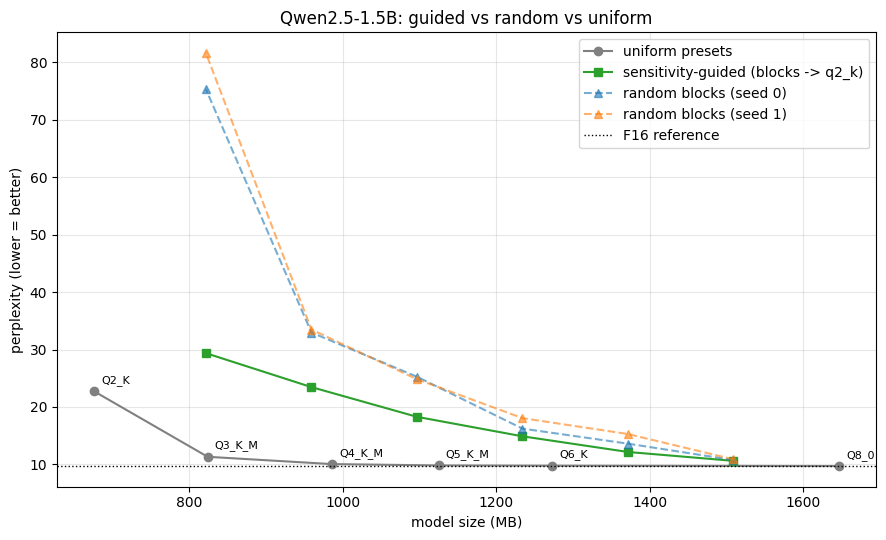

In [12]:
df = pd.DataFrame(records.values())

g = df[df.group == "guided"].sort_values("size_mb", ascending=False)
rnd = df[df.group == "random"]
uni = pd.concat([df[df.name == "ref_HIGH"], df[df.group == "uniform"]]).sort_values("size_mb", ascending=False)

cmp = g[["n_low", "size_mb", "ppl"]].rename(columns={"ppl": "guided_ppl"}).merge(
    rnd.groupby("n_low").ppl.mean().rename("random_mean_ppl").reset_index(), on="n_low")
cmp["guided_better_by_pct"] = (cmp.random_mean_ppl / cmp.guided_ppl - 1) * 100
display(cmp.round(3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(uni.size_mb, uni.ppl, "o-", color="gray", label="uniform presets")
for _, r in uni.iterrows():
    ax.annotate(r["name"].replace("uniform_", "").replace("ref_HIGH", "Q8_0"),
                (r.size_mb, r.ppl), textcoords="offset points", xytext=(5, 6), fontsize=8)
ax.plot(g.size_mb, g.ppl, "s-", color="tab:green", label=f"sensitivity-guided (blocks -> {low})")
for seed, s in rnd.groupby("seed"):
    s = s.sort_values("size_mb", ascending=False)
    ax.plot(s.size_mb, s.ppl, "^--", alpha=.6, label=f"random blocks (seed {int(seed)})")
ax.axhline(records["ref_F16"]["ppl"], color="k", ls=":", lw=1, label="F16 reference")
ax.set_xlabel("model size (MB)"); ax.set_ylabel("perplexity (lower = better)")
ax.set_title(f"{MODEL_NAME}: guided vs random vs uniform"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / f"phase2_{MODEL_NAME}_guided_vs_uniform.png", dpi=150)
plt.show()

## 10. Save everything, then clean up
Results go to CSV/JSON. The big model files are deleted at the end (`CLEANUP`) so that **Save Version** does not spend ages packaging gigabytes.

In [13]:
df.to_csv(RESULTS / f"phase2_{MODEL_NAME}.csv", index=False)
meta = {
    "model": MODEL_ID, "llama_cpp_commit": LLAMA_COMMIT, "n_blocks": N_BLOCKS,
    "high": HIGH, "low_types": LOW_TYPES, "ppl_chunks": PPL_CHUNKS,
    "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
    "date": time.strftime("%Y-%m-%d %H:%M"),
    "compression_order": order_guided,
}
(RESULTS / f"phase2_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

if CLEANUP:
    shutil.rmtree(WORK / "hf", ignore_errors=True)
    shutil.rmtree(MODELS, ignore_errors=True)
    print(sh(f"du -sh {WORK}", check=False))

$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
{
  "model": "Qwen/Qwen2.5-1.5B",
  "llama_cpp_commit": "970b51c",
  "n_blocks": 28,
  "high": "q8_0",
  "low_types": [
    "q2_k"
  ],
  "ppl_chunks": 100,
  "gpu": "Tesla T4",
  "date": "2026-10-22 19:59",
  "compression_order": [
    7,
    4,
    10,
    6,
    9,
    11,
    14,
    12,
    8,
    13,
    16,
    15,
    17,
    3,
    20,
    18,
    23,
    24,
    22,
    5,
    19,
    25,
    26,
    21,
    2,
    0,
    1,
    27
  ]
}
$ du -sh /kaggle/working
431M	/kaggle/working


## What to look for
1. **Is sensitivity uneven?** Typically the first and last blocks are the most sensitive and the middle ones are tolerant. A flat profile would mean there is little to gain from mixed precision.
2. **Which tensor kinds hurt most?** Often `ffn_down` and `attn_v` are the most sensitive and `ffn_gate`/`ffn_up` more tolerant (tell me what you see).
3. **Does the green line sit below the random lines and the uniform curve** at equal size? That is the evidence Phase 3's search needs.
4. **Next (Phase 3):** automatic search over per-block (and per-kind) precision choices with several precision levels, using these sensitivities to shrink the search space and to seed the first candidates.

*Tip: `llama-quantize` also has `--prune-layers`, which could become a pruning extension later.*